# Part 7: How much data is enough?

Four approaches were run on samples of 50, 100, 200, 500 and 1,000 labelled reviews and scored on the validation split. Sizes up to 200 were repeated with three seeds (42, 1 and 2), and 500 and 1,000 were run once, with seed 42. A full run takes about 20 minutes on a CPU per seed, so the results are saved in `small_data_results_seed*.csv`. To repeat one, run `python curves.py 42` from this folder (it uses every size).

In [1]:
import glob

import pandas as pd

results = pd.concat(pd.read_csv(f) for f in sorted(glob.glob("small_data_results_seed*.csv")))
order = ["tfidf", "frozen features", "head only", "full fine-tune"]
summary = results.groupby(["n", "method"])["accuracy"].agg(["mean", "min", "max", "count"])
summary = summary.round(3).reset_index()
summary.pivot(index="n", columns="method", values="mean")[order]

method,tfidf,frozen features,head only,full fine-tune
n,,,,
50,0.528,0.680,0.649,0.607
100,0.556,0.702,0.691,0.661
200,0.597,0.730,0.737,0.740
500,0.636,0.734,0.753,0.783
1000,0.649,0.776,0.792,0.809


In [2]:
# the spread across seeds: lowest and highest accuracy for each approach
spread = summary.assign(range=lambda t: t["max"] - t["min"])
spread.pivot(index="n", columns="method", values="range")[order].round(3)

method,tfidf,frozen features,head only,full fine-tune
n,,,,
50,0.074,0.031,0.087,0.050
100,0.048,0.020,0.058,0.132
200,0.042,0.026,0.057,0.107
500,0.000,0.000,0.000,0.000
1000,0.000,0.000,0.000,0.000


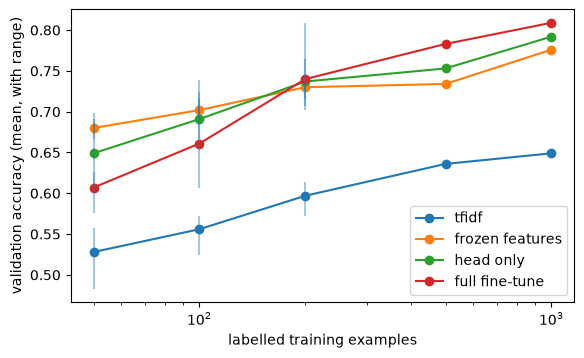

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for method in order:
    part = summary[summary.method == method]
    ax.plot(part["n"], part["mean"], marker="o", label=method)
    ax.vlines(part["n"], part["min"], part["max"], alpha=0.4)
ax.set_xscale("log")
ax.set_xlabel("labelled training examples")
ax.set_ylabel("validation accuracy (mean, with range)")
ax.legend()
plt.show()

## Read the table

- Every pretrained approach beats the word-count baseline in every run.
- With 50 and 100 examples, **frozen features** have the best mean and the narrowest range.
- **Full fine-tuning** varies the most from seed to seed: at 200 examples its runs range from about 0.70 to 0.81. One run could make it look best or worst.
- At 500 and 1,000 examples (one run each) full fine-tuning is best by a few points. Repeat with other seeds before you trust that.

## Try it

1. Compare the 50-example rows across the three seeds. How much does full fine-tuning change?
2. At which size would you pick full fine-tuning over frozen features? Does it depend on how much computing time you have?
3. Which method would you ship with 100 labelled examples, and how would you explain the choice to someone who has seen only one run?